# Week 05 · Monte-Carlo Prediction — 몬테카를로 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week05_model_free_prediction/01_monte_carlo_prediction.ipynb)

슬라이드 **"First-Visit Monte-Carlo Policy Evaluation"**, **"Every-Visit Monte-Carlo Policy Evaluation"**,
**"Blackjack Example"**, **"Blackjack Value Function after Monte-Carlo Learning"**, **"Incremental Mean"**,
**"Incremental Monte-Carlo Updates"** 를 코드로 재현합니다.
모델(전이 확률)을 전혀 쓰지 않고 **에피소드를 끝까지 진행한 뒤 얻은 리턴의 평균**만으로 가치 함수(value function)를
추정하는 과정을 보고, Sutton & Barto(S&B) Figure 5.1의 블랙잭 가치 함수를 직접 그려 봅니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 노트북 전용
import time
from matplotlib.colors import Normalize
np.set_printoptions(precision=3, suppress=True, linewidth=120)

## 1. First-Visit vs. Every-Visit MC (First-Visit / Every-Visit Monte-Carlo Policy Evaluation)

정책 $\pi$를 따라 얻은 에피소드에서 상태 $s$를 만날 때마다 리턴 $G_t$를 모아 평균을 냅니다.

- **First-visit MC**: 한 에피소드에서 $s$를 **처음** 방문한 시점의 $G_t$만 사용
- **Every-visit MC**: $s$를 방문한 **모든** 시점의 $G_t$를 사용

두 방법 모두 $N(s) \leftarrow N(s)+1$, $S(s) \leftarrow S(s)+G_t$, $V(s) = S(s)/N(s)$ 로 계산합니다.
상태가 한 에피소드 안에서 여러 번 나타나야 차이가 생기므로, 뒤의 TD 노트북에서도 쓰는
**5-상태 Random Walk**(A–E, 가운데 C에서 시작, 좌우로 1/2 확률 이동, 오른쪽 끝 도착 시 보상 +1, 나머지 0)를 사용합니다.
참 가치는 $v_\pi = (1/6, 2/6, 3/6, 4/6, 5/6)$ 입니다.

In [2]:
# 5-state random walk: index 0 = left terminal, 1..5 = A..E, 6 = right terminal
LEFT_T, RIGHT_T, START = 0, 6, 3
NAMES = ["T", "A", "B", "C", "D", "E", "T"]
TRUE_V = np.array([0, 1, 2, 3, 4, 5, 0]) / 6          # terminal values are 0


def generate_episode(rng):
    """One episode of the random walk. Returns states S_0..S_T (last one terminal) and rewards R_1..R_T."""
    s = START
    states, rewards = [s], []
    while s not in (LEFT_T, RIGHT_T):
        s = s + 1 if rng.random() < 0.5 else s - 1
        states.append(s)
        rewards.append(1.0 if s == RIGHT_T else 0.0)
    return states, rewards


def returns_of(rewards, gamma):
    """G_t = R_{t+1} + gamma * G_{t+1}, computed backwards."""
    G = np.zeros(len(rewards))
    g = 0.0
    for t in reversed(range(len(rewards))):
        g = rewards[t] + gamma * g
        G[t] = g
    return G


def mc_prediction(episodes, gamma=1.0, first_visit=True, n_states=7):
    """Sample-average MC policy evaluation exactly as on the slides: N(s), S(s), V(s) = S(s)/N(s)."""
    N = np.zeros(n_states)
    S = np.zeros(n_states)
    for states, rewards in episodes:
        G = returns_of(rewards, gamma)
        seen = set()
        for t in range(len(rewards)):          # S_T (terminal) is never updated
            s = states[t]
            if first_visit and s in seen:
                continue
            seen.add(s)
            N[s] += 1
            S[s] += G[t]
    V = np.divide(S, N, out=np.full(n_states, np.nan), where=N > 0)
    return V, N, S

### 손으로 따라가 보기

S&B 예제 6.2의 "전형적인 에피소드" $C,0,B,0,C,0,D,0,E,1$ 하나로 두 방법을 비교합니다.
Random walk는 원래 할인이 없지만($\gamma=1$이면 모든 리턴이 1이라 평균이 같아짐), 차이를 눈으로 보기 위해 여기서만 $\gamma=0.9$를 씁니다.
C는 $t=0$과 $t=2$에 두 번 방문하므로 $G_0 = 0.9^4 = 0.6561$, $G_2 = 0.9^2 = 0.81$ 입니다.

In [3]:
episode = ([3, 2, 3, 4, 5, 6], [0.0, 0.0, 0.0, 0.0, 1.0])   # C, B, C, D, E, T
print("returns G_t :", returns_of(episode[1], 0.9))

for first in (True, False):
    V, N, S = mc_prediction([episode], gamma=0.9, first_visit=first)
    name = "first-visit" if first else "every-visit"
    print(f"\n{name:12s} state:  " + "  ".join(f"{NAMES[s]:>6s}" for s in range(1, 6)))
    print(f"{'':12s} N(s):   " + "  ".join(f"{N[s]:6.0f}" for s in range(1, 6)))
    print(f"{'':12s} S(s):   " + "  ".join(f"{S[s]:6.4f}" for s in range(1, 6)))
    print(f"{'':12s} V(s):   " + "  ".join(f"{V[s]:6.4f}" if N[s] else "     -" for s in range(1, 6)))

V_first, _, _ = mc_prediction([episode], gamma=0.9, first_visit=True)
V_every, _, _ = mc_prediction([episode], gamma=0.9, first_visit=False)
assert np.isclose(V_first[3], 0.9**4) and np.isclose(V_every[3], (0.9**4 + 0.9**2) / 2)

returns G_t : [0.656 0.729 0.81  0.9   1.   ]

first-visit  state:       A       B       C       D       E
             N(s):        0       1       1       1       1
             S(s):   0.0000  0.7290  0.6561  0.9000  1.0000
             V(s):        -  0.7290  0.6561  0.9000  1.0000

every-visit  state:       A       B       C       D       E
             N(s):        0       1       2       1       1
             S(s):   0.0000  0.7290  1.4661  0.9000  1.0000
             V(s):        -  0.7290  0.7331  0.9000  1.0000


C만 값이 다릅니다: first-visit은 $0.6561$, every-visit은 $(0.6561+0.81)/2 = 0.7331$.
이제 원래 설정($\gamma=1$)으로 돌아가 에피소드 수를 늘리면서 두 방법의 RMS 오차(5개 상태 평균)를 100번 반복 평균으로 비교합니다.
아직 방문하지 않은 상태의 추정값은 0.5로 둡니다.

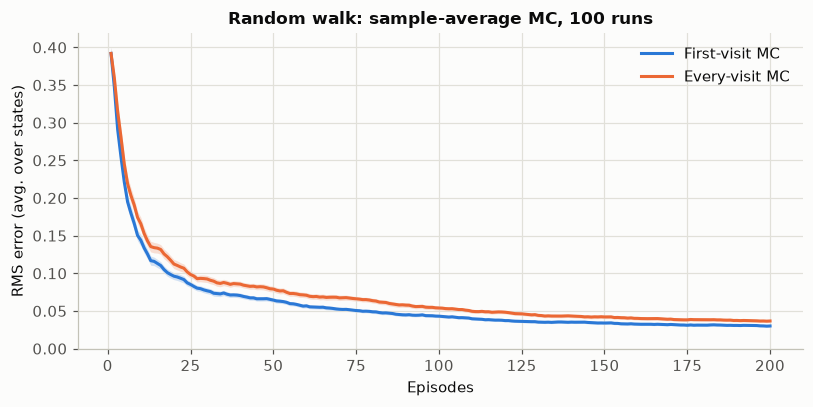

first-visit: RMS after 10 / 50 / 200 episodes = 0.144 / 0.064 / 0.030
every-visit: RMS after 10 / 50 / 200 episodes = 0.166 / 0.079 / 0.037


In [4]:
def mc_learning_curve(episodes, first_visit, default=0.5):
    """RMS error of the sample-average MC estimate after each episode (gamma = 1)."""
    N = np.zeros(7)
    S = np.zeros(7)
    errors = []
    for states, rewards in episodes:
        G = returns_of(rewards, 1.0)
        seen = set()
        for t in range(len(rewards)):
            s = states[t]
            if first_visit and s in seen:
                continue
            seen.add(s)
            N[s] += 1
            S[s] += G[t]
        V = np.where(N > 0, S / np.maximum(N, 1), default)
        errors.append(np.sqrt(np.mean((V[1:6] - TRUE_V[1:6]) ** 2)))
    return np.array(errors)


n_runs, n_episodes = 100, 200
rng = np.random.default_rng(1)
curves = {True: [], False: []}
for run in range(n_runs):
    eps = [generate_episode(rng) for _ in range(n_episodes)]
    for first in (True, False):
        curves[first].append(mc_learning_curve(eps, first))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(1, n_episodes + 1)
for first, color in ((True, PALETTE[0]), (False, PALETTE[1])):
    c = np.array(curves[first])
    m, se = c.mean(0), c.std(0) / np.sqrt(n_runs)
    label = "First-visit MC" if first else "Every-visit MC"
    ax.plot(x, m, color=color, label=label)
    ax.fill_between(x, m - se, m + se, color=color, alpha=0.2, lw=0)
ax.set_xlabel("Episodes")
ax.set_ylabel("RMS error (avg. over states)")
ax.set_title("Random walk: sample-average MC, 100 runs")
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.show()
for first in (True, False):
    c = np.array(curves[first])
    print(f"{'first' if first else 'every'}-visit: RMS after 10 / 50 / 200 episodes = "
          f"{c[:, 9].mean():.3f} / {c[:, 49].mean():.3f} / {c[:, -1].mean():.3f}")

두 곡선 모두 에피소드가 늘수록 0으로 내려갑니다(대수의 법칙, $V(s) \to v_\pi(s)$).
이 문제에서는 every-visit의 오차가 조금 더 큽니다. $\gamma=1$이고 보상이 종료 때만 나오므로 한 에피소드 안의 리턴은 모두 같습니다.
그래서 every-visit이 더 모으는 샘플은 새 정보가 없는 복사본이고, 상태를 여러 번 오간 에피소드에 더 큰 가중치를 줄 뿐입니다.
(every-visit 추정량은 유한 표본에서 편향이 있지만 일치 추정량이라 결국 같은 값으로 수렴합니다.)

## 2. Blackjack (Blackjack Example, Blackjack Value Function after Monte-Carlo Learning)

슬라이드의 설정 (S&B 예제 5.1):

- 상태 200개: 플레이어 합(12–21) × 딜러가 보여준 카드(A–10) × 사용 가능한 에이스(usable ace) 여부
- 행동: **hit**(카드 한 장 더) / **stand(stick)**. 합이 12 미만이면 자동으로 hit (버스트할 수 없으므로 결정할 것이 없음)
- 보상: hit 후 버스트(합 > 21)면 $-1$; stand 후 딜러와 비교해 이기면 $+1$, 지면 $-1$, 비기면 $0$. $\gamma = 1$
- 딜러: 합이 17 이상이면 stick, 아니면 hit (고정 전략). 카드는 **무한 덱**(복원 추출), J/Q/K = 10
- 평가할 정책: **합이 20 또는 21이면 stand, 아니면 hit**

책의 규칙 한 가지를 더 넣었습니다: 처음 두 장이 에이스+10(**natural**)이면 딜러도 natural이 아닌 한 이깁니다(딜러도 natural이면 무승부).

카드가 복원 추출이므로 카드를 미리 한꺼번에 뽑아 두고 차례로 꺼내 써도 확률적으로 똑같습니다(속도를 위한 선택).

In [5]:
def card_stream(rng, chunk=1_000_000):
    """Infinite deck: an endless stream of i.i.d. cards (ace = 1, face cards = 10)."""
    while True:
        yield from np.minimum(rng.integers(1, 14, size=chunk), 10).tolist()


def hand_value(total, has_ace):
    """Best value of a hand whose aces are counted as 1 in `total`. Returns (value, usable_ace)."""
    if has_ace and total + 10 <= 21:
        return total + 10, True
    return total, False


def dealer_final_sum(showing, hidden, cards):
    """The dealer hits until his sum is >= 17 (a usable ace counts as 11)."""
    total, has_ace = showing + hidden, (showing == 1 or hidden == 1)
    while hand_value(total, has_ace)[0] < 17:
        c = next(cards)
        total, has_ace = total + c, has_ace or c == 1
    return hand_value(total, has_ace)[0]


def play_episode(cards, stick_at=20):
    """Play one game with the policy 'stick on sum >= stick_at, otherwise hit'.

    Returns the list of visited states (player_sum, usable_ace, dealer_showing) and the final reward
    (= the return G for every visited state, since gamma = 1 and all other rewards are 0).
    """
    p1, p2, showing, hidden = next(cards), next(cards), next(cards), next(cards)
    total, has_ace = p1 + p2, (p1 == 1 or p2 == 1)
    player_natural = hand_value(total, has_ace)[0] == 21
    dealer_natural = hand_value(showing + hidden, showing == 1 or hidden == 1)[0] == 21

    while hand_value(total, has_ace)[0] < 12:          # automatic hits: no decision to make
        c = next(cards)
        total, has_ace = total + c, has_ace or c == 1

    states = []
    while True:
        value, usable = hand_value(total, has_ace)
        if value > 21:
            return states, -1                           # bust
        states.append((value, usable, showing))
        if value >= stick_at:
            break                                       # stick
        c = next(cards)                                 # hit
        total, has_ace = total + c, has_ace or c == 1

    if player_natural:
        return states, (0 if dealer_natural else 1)
    dealer = dealer_final_sum(showing, hidden, cards)
    if dealer > 21 or value > dealer:
        return states, 1
    return states, (-1 if value < dealer else 0)


def to_index(state):
    """(player_sum 12..21, usable, dealer 1..10) -> array index."""
    value, usable, showing = state
    return value - 12, showing - 1, int(usable)

In [6]:
def evaluate_blackjack(n_episodes, seed=0, snapshots=(), stick_at=20):
    """First-visit MC with N(s), S(s). Returns a dict {episode count: V} for each snapshot and the final N."""
    cards = card_stream(np.random.default_rng(seed))
    N = np.zeros((10, 10, 2))      # [player_sum-12, dealer-1, usable]
    S = np.zeros((10, 10, 2))
    V_at = {}
    for k in range(1, n_episodes + 1):
        states, G = play_episode(cards, stick_at)
        for state in states:        # states never repeat within a game -> first-visit == every-visit
            N[to_index(state)] += 1
            S[to_index(state)] += G
        if k in snapshots or k == n_episodes:
            V_at[k] = S / np.maximum(N, 1)
    return V_at, N


t0 = time.time()
V_at, N_bj = evaluate_blackjack(500_000, seed=0, snapshots=(10_000,))
print(f"500,000 episodes simulated in {time.time() - t0:.1f} s")
print("fewest visits of any state after 500,000 episodes:", int(N_bj.min()))

500,000 episodes simulated in 0.5 s
fewest visits of any state after 500,000 episodes: 215


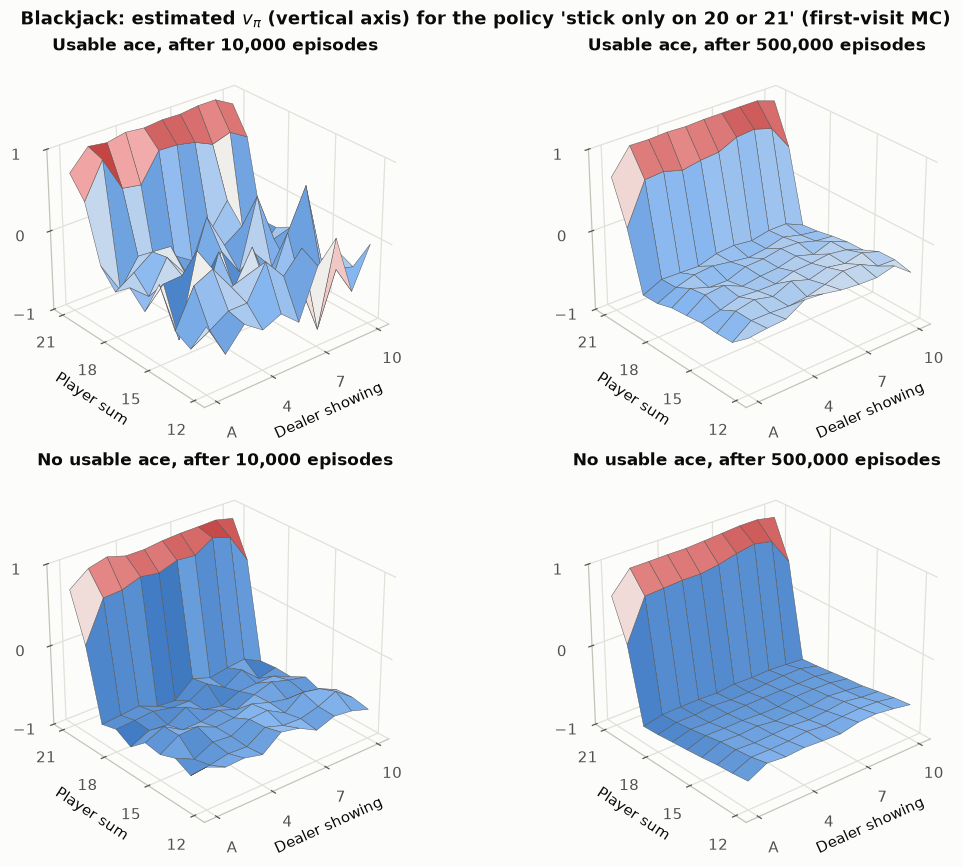

In [7]:
def plot_value_surface(ax, V2d, title):
    """3-D surface of V over (dealer showing, player sum), colored with the diverging map."""
    dealer, player = np.meshgrid(np.arange(1, 11), np.arange(12, 22))
    colors = DIV_CMAP(Normalize(-1, 1)(V2d))
    ax.plot_surface(dealer, player, V2d, facecolors=colors, edgecolor="#52514e", linewidth=0.3,
                    rstride=1, cstride=1, shade=False)
    ax.set_zlim(-1, 1)
    ax.set_xticks([1, 4, 7, 10], ["A", "4", "7", "10"])
    ax.set_yticks([12, 15, 18, 21])
    ax.set_zticks([-1, 0, 1])
    ax.set_xlabel("Dealer showing", labelpad=2)
    ax.set_ylabel("Player sum", labelpad=2)
    ax.set_title(title, pad=0)
    ax.view_init(elev=28, azim=-130)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((0.99, 0.99, 0.985, 1.0))


fig = plt.figure(figsize=(10, 8))
for col, k in enumerate((10_000, 500_000)):
    for row, usable in enumerate((1, 0)):
        ax = fig.add_subplot(2, 2, 2 * row + col + 1, projection="3d")
        label = "Usable ace" if usable else "No usable ace"
        plot_value_surface(ax, V_at[k][:, :, usable], f"{label}, after {k:,} episodes")
fig.suptitle(r"Blackjack: estimated $v_\pi$ (vertical axis) for the policy 'stick only on 20 or 21' (first-visit MC)",
             fontweight="bold")
fig.subplots_adjust(left=0.03, right=0.97, top=0.93, bottom=0.03, wspace=0.1, hspace=0.1)
plt.show()

같은 결과를 숫자로 읽기 쉽게 히트맵으로도 봅니다(500,000 에피소드 후).

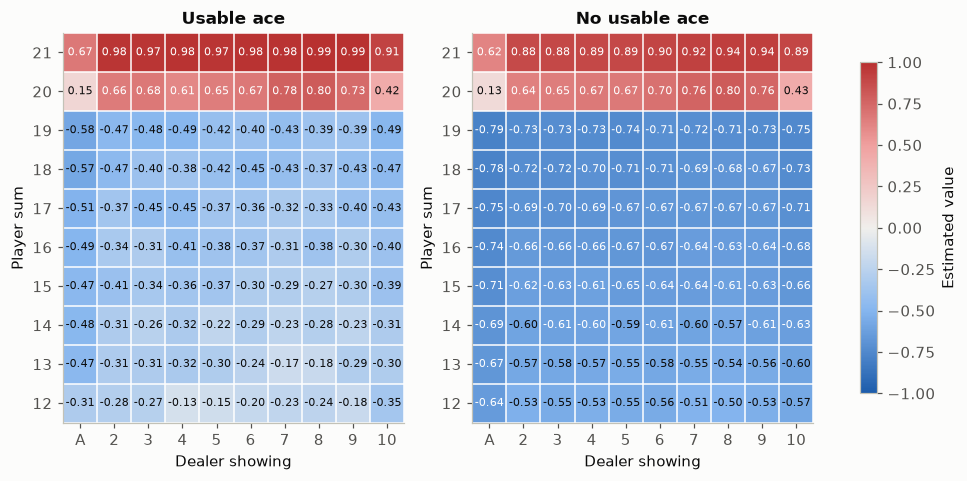

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
V_final = V_at[500_000]
for ax, usable in zip(axes, (1, 0)):
    V2d = V_final[:, :, usable]
    im = ax.imshow(V2d, origin="lower", cmap=DIV_CMAP, vmin=-1, vmax=1, aspect="auto")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{V2d[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(V2d[i, j]) > 0.6 else "#0b0b0b")
    ax.set_xticks(range(10), ["A"] + [str(c) for c in range(2, 11)])
    ax.set_yticks(range(10), [str(s) for s in range(12, 22)])
    ax.set_xticks(np.arange(-0.5, 10), minor=True)
    ax.set_yticks(np.arange(-0.5, 10), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", length=0)
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    ax.set_title("Usable ace" if usable else "No usable ace")
fig.colorbar(im, ax=axes, shrink=0.85, label="Estimated value")
plt.show()

### 슬라이드와 비교

슬라이드(와 S&B Figure 5.1)는 그림만 있으므로 모양을 비교합니다. 아래 셀은 그림에서 읽히는 특징을 수치로 확인합니다.

1. 합이 **20, 21**인 두 줄에서 값이 급격히 올라갑니다 — 이 정책은 20, 21에서만 멈추기 때문입니다(19 이하면 계속 hit → 대부분 버스트).
2. 딜러가 **에이스**를 보여 주는 열은 값이 낮습니다 — 딜러가 강한 패를 만들 가능성이 큽니다.
3. **Usable ace**가 있으면 12–19 구간 값이 더 높습니다 — 한 번 더 받아도 에이스를 1로 바꾸면 버스트하지 않습니다.
4. Usable ace 상태는 드물게 방문되므로 10,000 에피소드에서는 표면이 울퉁불퉁하고, 500,000 에피소드에서는 매끈해집니다.

In [9]:
V = V_at[500_000]
low_rows = V[:8]                     # player sum 12..19
high_rows = V[8:]                    # player sum 20, 21
print("mean V, sums 12-19 (no usable / usable):", low_rows[:, :, 0].mean().round(3), low_rows[:, :, 1].mean().round(3))
print("mean V, sums 20-21 (no usable / usable):", high_rows[:, :, 0].mean().round(3), high_rows[:, :, 1].mean().round(3))
print("V(sum 20, no usable ace) by dealer card A..10:", V[8, :, 0].round(2))

roughness = {k: np.abs(np.diff(V_at[k][:8, :, 1], axis=1)).mean() for k in (10_000, 500_000)}
print("mean |neighbour difference| on the usable-ace surface (sums 12-19):",
      {k: round(v, 3) for k, v in roughness.items()})

assert (low_rows < 0).all() and (high_rows[:, 1:] > 0).all()              # (1) jump at 20, 21
assert (V[8:, 0, :] < V[8:, 1:, :].mean(axis=1)).all()                     # (2) dealer ace column lower
assert low_rows[:, :, 1].mean() > low_rows[:, :, 0].mean()                 # (3) usable ace helps
assert roughness[10_000] > 2 * roughness[500_000]                          # (4) smoother with more data

mean V, sums 12-19 (no usable / usable): -0.647 -0.353
mean V, sums 20-21 (no usable / usable): 0.748 0.779
V(sum 20, no usable ace) by dealer card A..10: [0.13 0.64 0.65 0.67 0.67 0.7  0.76 0.8  0.76 0.43]
mean |neighbour difference| on the usable-ace surface (sums 12-19): {10000: np.float64(0.358), 500000: np.float64(0.055)}


네 가지 특징 모두 슬라이드 그림과 일치합니다. 참고로 이 게임에서는 한 에피소드 안에서 같은 상태가 두 번 나오지 않으므로
(플레이어 합이 계속 커짐) first-visit MC와 every-visit MC는 완전히 같은 결과를 줍니다(S&B 연습문제 5.2).
500,000 에피소드도 몇 초 안에 끝나므로 책과 같은 에피소드 수를 그대로 사용했습니다.

## 3. Incremental Mean (Incremental Mean, Incremental Monte-Carlo Updates)

평균은 지난 값을 모두 저장하지 않고도 갱신할 수 있습니다:
$$\mu_k = \mu_{k-1} + \frac{1}{k}\left(x_k - \mu_{k-1}\right).$$
그래서 MC 평가도 $N(S_t) \leftarrow N(S_t)+1$, $V(S_t) \leftarrow V(S_t) + \frac{1}{N(S_t)}\left(G_t - V(S_t)\right)$ 로 쓸 수 있습니다.
먼저 이 식이 보통의 평균과 정확히 같은지 확인합니다.

In [10]:
def incremental_mean(xs):
    """All running means mu_1..mu_k using mu_k = mu_{k-1} + (x_k - mu_{k-1}) / k."""
    mu, out = 0.0, []
    for k, x in enumerate(xs, start=1):
        mu = mu + (x - mu) / k
        out.append(mu)
    return np.array(out)


xs = np.random.default_rng(2).normal(3.0, 2.0, size=1000)
mus = incremental_mean(xs)
batch_means = np.cumsum(xs) / np.arange(1, len(xs) + 1)
print("incremental mu_1000 =", mus[-1].round(6), "  np.mean =", xs.mean().round(6))
assert np.allclose(mus, batch_means)

incremental mu_1000 = 2.955182   np.mean = 2.955182


블랙잭에서도 확인해 봅니다. 같은 시드(같은 카드 순서)로 $V \leftarrow V + \frac{1}{N}(G - V)$ 만 사용해 10,000 에피소드를 평가하면,
앞에서 $S(s)/N(s)$로 구한 값과 같아야 합니다.

In [11]:
def evaluate_blackjack_incremental(n_episodes, seed=0, alpha=None):
    """Incremental MC: step size 1/N(s) (alpha=None) or a constant alpha."""
    cards = card_stream(np.random.default_rng(seed))
    N = np.zeros((10, 10, 2))
    V = np.zeros((10, 10, 2))
    for _ in range(n_episodes):
        states, G = play_episode(cards)
        for state in states:
            idx = to_index(state)
            N[idx] += 1
            step = 1.0 / N[idx] if alpha is None else alpha
            V[idx] += step * (G - V[idx])
    return V


V_inc = evaluate_blackjack_incremental(10_000, seed=0)
print("max |V_incremental - S/N| after 10,000 episodes:", np.abs(V_inc - V_at[10_000]).max())
assert np.allclose(V_inc, V_at[10_000])

max |V_incremental - S/N| after 10,000 episodes: 5.551115123125783e-16


### 비정상(non-stationary) 문제에서의 running mean

슬라이드의 마지막 줄: 환경이 변하는 문제에서는 $\frac{1}{N}$ 대신 상수 $\alpha$를 써서 오래된 에피소드를 잊는 편이 낫습니다.
평균이 $k=300$에서 0 → 1로 바뀌는 잡음 섞인 수열로 $\frac{1}{k}$ 평균과 상수 $\alpha$ running mean을 비교합니다.

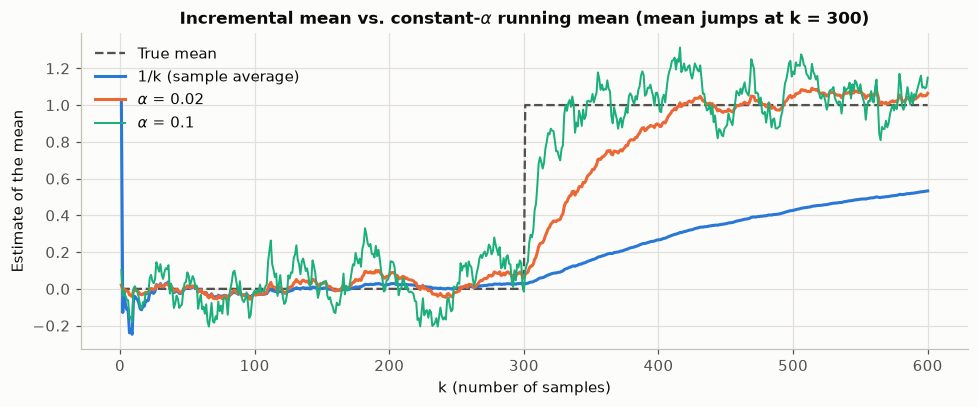

estimate at k = 600:  1/k -> 0.533,  alpha=0.02 -> 1.064,  alpha=0.1 -> 1.149


In [12]:
k_all = np.arange(1, 601)
true_mean = np.where(k_all <= 300, 0.0, 1.0)
xs = true_mean + np.random.default_rng(3).normal(0, 0.5, size=len(k_all))


def running_mean(xs, alpha):
    """mu_k = mu_{k-1} + alpha * (x_k - mu_{k-1}), mu_0 = 0."""
    mu, out = 0.0, []
    for x in xs:
        mu = mu + alpha * (x - mu)
        out.append(mu)
    return np.array(out)


fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(k_all, true_mean, color="#52514e", ls="--", lw=1.5, label="True mean")
ax.plot(k_all, incremental_mean(xs), color=PALETTE[0], label="1/k (sample average)")
ax.plot(k_all, running_mean(xs, 0.02), color=PALETTE[1], label=r"$\alpha$ = 0.02")
ax.plot(k_all, running_mean(xs, 0.1), color=PALETTE[2], lw=1.3, label=r"$\alpha$ = 0.1")
ax.set_xlabel("k (number of samples)")
ax.set_ylabel("Estimate of the mean")
ax.set_title(r"Incremental mean vs. constant-$\alpha$ running mean (mean jumps at k = 300)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("estimate at k = 600:  1/k -> %.3f,  alpha=0.02 -> %.3f,  alpha=0.1 -> %.3f"
      % (incremental_mean(xs)[-1], running_mean(xs, 0.02)[-1], running_mean(xs, 0.1)[-1]))

$\frac{1}{k}$ 평균은 변화 이전 300개 샘플을 똑같이 기억하므로 $k=600$에서도 0.5 근처에 머뭅니다.
상수 $\alpha$는 최근 샘플에 지수적으로 큰 가중치를 주어 새 평균(1)을 따라가며, $\alpha$가 클수록 빨리 따라가지만 잡음도 큽니다.
이 상수-$\alpha$ 갱신 $V(S_t) \leftarrow V(S_t) + \alpha(G_t - V(S_t))$ 가 다음 노트북에서 TD와 비교하는 constant-$\alpha$ MC입니다.

## 직접 해보기

1. `play_episode(cards, stick_at=...)`의 기준을 18이나 17로 바꿔 `evaluate_blackjack`을 다시 돌려 보세요. 표면의 "절벽"이 어디로 옮겨 가고, 12–19 구간 값이 얼마나 올라가나요?
2. `dealer_final_sum`을 "soft 17에서도 hit"하도록 바꾸면(usable ace가 있는 17이면 한 장 더) 플레이어의 가치가 어떻게 변하는지 히트맵으로 비교해 보세요.
3. 1절의 learning curve에서 `n_episodes`를 1000으로 늘리고, 에피소드 수 대비 RMS 오차가 대략 $1/\sqrt{n}$으로 줄어드는지 로그-로그 축으로 확인해 보세요.
4. `evaluate_blackjack_incremental(..., alpha=0.01)`처럼 상수 $\alpha$를 쓰면 500,000 에피소드 후에도 추정값이 계속 흔들립니다. 히트맵에서 $1/N$ 결과와의 차이를 확인해 보세요.